# 🌲 Random Forest from Scratch

A Random Forest is an **ensemble** of many Decision Trees. Instead of relying on a single tree (which can overfit and be unstable), it builds many trees on randomized subsets of the data and features, then combines their predictions by **majority vote**.

This notebook builds directly on the `Decision Tree` notebook — make sure you've gone through that one first, since we reuse the same `DecisionTreeScratch` class as the building block here.

## 📖 What You'll Learn
1. The intuition behind ensembles and why "many weak trees" beat "one strong tree"
2. Bootstrap Aggregating (**Bagging**)
3. Random feature subsampling at each split
4. Implementing a Random Forest **from scratch** using our Decision Tree as a base
5. Comparing our implementation with scikit-learn's `RandomForestClassifier`
6. The effect of `n_estimators` (number of trees) on performance and stability
7. Evaluating with accuracy, confusion matrix, and classification report
8. Feature importance and decision boundary visualization

## 📊 Dataset
We'll use the **[Iris dataset](https://scikit-learn.org/stable/datasets/toy_dataset.html#iris-plants-dataset)**, the same dataset used in the KNN and Decision Tree notebooks, so results are directly comparable.

## 1. Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

sns.set_style("whitegrid")
np.random.seed(42)

## 2. Load and Explore the Dataset

In [2]:
data = load_iris()
X = data.data
y = data.target
feature_names = data.feature_names

df = pd.DataFrame(X, columns=feature_names)
df['species'] = pd.Categorical.from_codes(y, data.target_names)

print("Shape of dataset:", X.shape)
print("Classes:", data.target_names)
df.head()

Shape of dataset: (150, 4)
Classes: ['setosa' 'versicolor' 'virginica']


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## 3. The Intuition and Math Behind Random Forests

### 3.1 Why Ensembles Work

A single Decision Tree has **high variance** — small changes in the training data can produce a very different tree (we saw this in the previous notebook). Random Forests reduce variance by combining many trees trained on randomized data, following the idea that **averaging many noisy, roughly-unbiased models cancels out their individual errors**.

### 3.2 Bootstrap Aggregating (Bagging)

For each tree in the forest:
1. Draw a **bootstrap sample** — sample $n$ data points **with replacement** from the training set (some points appear multiple times, ~37% are left out on average).
2. Train a Decision Tree on this bootstrap sample.

$$
D_t = \{(x_i, y_i) \text{ sampled with replacement from } D, \; i = 1, \dots, n\}, \quad t = 1, \dots, T
$$

### 3.3 Random Feature Subsampling

To further decorrelate the trees (so they don't all make the same mistakes), at **each split**, only a random subset of features is considered — typically $\sqrt{p}$ features for classification, where $p$ is the total number of features.

### 3.4 Combining Predictions

For classification, the final prediction is the **majority vote** across all $T$ trees:

$$
\hat{y} = \text{mode}\{h_1(x), h_2(x), \dots, h_T(x)\}
$$

where each $h_t$ is one Decision Tree in the forest.

## 4. Reusing the Decision Tree from Scratch

We use the same `DecisionTreeScratch` implementation from the previous notebook, with one addition: support for considering only a **random subset of features** at each split (`max_features`).

In [3]:
class Node:
    """A single node in the tree -- either a decision node or a leaf."""
    def __init__(self, feature=None, threshold=None, left=None, right=None, *, value=None):
        self.feature = feature
        self.threshold = threshold
        self.left = left
        self.right = right
        self.value = value

    def is_leaf(self):
        return self.value is not None

In [4]:
class DecisionTreeScratch:
    def __init__(self, max_depth=5, min_samples_split=2, criterion='gini',
                 max_features=None, random_state=None):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.criterion = criterion
        self.max_features = max_features  # number of features to consider at each split
        self.rng = np.random.RandomState(random_state)
        self.root = None

    def _gini(self, y):
        counts = np.bincount(y)
        probabilities = counts / len(y)
        return 1 - np.sum(probabilities ** 2)

    def _entropy(self, y):
        counts = np.bincount(y)
        probabilities = counts / len(y)
        probabilities = probabilities[probabilities > 0]
        return -np.sum(probabilities * np.log2(probabilities))

    def _impurity(self, y):
        return self._entropy(y) if self.criterion == 'entropy' else self._gini(y)

    def _best_split(self, X, y):
        n_samples, n_features = X.shape
        best_gain = -1
        best_feature, best_threshold = None, None
        parent_impurity = self._impurity(y)

        # Randomly select a subset of features to consider (Random Forest trick)
        if self.max_features is not None:
            feature_indices = self.rng.choice(n_features, self.max_features, replace=False)
        else:
            feature_indices = range(n_features)

        for feature in feature_indices:
            thresholds = np.unique(X[:, feature])
            for threshold in thresholds:
                left_mask = X[:, feature] <= threshold
                right_mask = ~left_mask

                if left_mask.sum() == 0 or right_mask.sum() == 0:
                    continue

                n_left, n_right = left_mask.sum(), right_mask.sum()
                impurity_left = self._impurity(y[left_mask])
                impurity_right = self._impurity(y[right_mask])

                weighted_impurity = (n_left / n_samples) * impurity_left + \
                                     (n_right / n_samples) * impurity_right
                gain = parent_impurity - weighted_impurity

                if gain > best_gain:
                    best_gain = gain
                    best_feature = feature
                    best_threshold = threshold

        return best_feature, best_threshold, best_gain

    def _build_tree(self, X, y, depth=0):
        n_samples = len(y)
        n_classes = len(np.unique(y))

        if (depth >= self.max_depth or
            n_classes == 1 or
            n_samples < self.min_samples_split):
            leaf_value = Counter(y).most_common(1)[0][0]
            return Node(value=leaf_value)

        feature, threshold, gain = self._best_split(X, y)

        if feature is None or gain <= 0:
            leaf_value = Counter(y).most_common(1)[0][0]
            return Node(value=leaf_value)

        left_mask = X[:, feature] <= threshold
        right_mask = ~left_mask

        left_child = self._build_tree(X[left_mask], y[left_mask], depth + 1)
        right_child = self._build_tree(X[right_mask], y[right_mask], depth + 1)

        return Node(feature=feature, threshold=threshold, left=left_child, right=right_child)

    def fit(self, X, y):
        X, y = np.array(X), np.array(y)
        self.root = self._build_tree(X, y)
        return self

    def _traverse(self, x, node):
        if node.is_leaf():
            return node.value
        if x[node.feature] <= node.threshold:
            return self._traverse(x, node.left)
        else:
            return self._traverse(x, node.right)

    def predict(self, X):
        X = np.array(X)
        return np.array([self._traverse(x, self.root) for x in X])

## 5. Implementing Random Forest from Scratch

Now we build the forest: an ensemble that trains many `DecisionTreeScratch` instances on bootstrap samples and combines them with majority voting.

In [5]:
class RandomForestScratch:
    def __init__(self, n_estimators=100, max_depth=5, min_samples_split=2,
                 criterion='gini', max_features='sqrt', random_state=42):
        self.n_estimators = n_estimators
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.criterion = criterion
        self.max_features = max_features
        self.random_state = random_state
        self.trees = []

    def _bootstrap_sample(self, X, y, rng):
        n_samples = X.shape[0]
        indices = rng.choice(n_samples, size=n_samples, replace=True)
        return X[indices], y[indices]

    def _resolve_max_features(self, n_features):
        if self.max_features == 'sqrt':
            return max(1, int(np.sqrt(n_features)))
        elif self.max_features == 'log2':
            return max(1, int(np.log2(n_features)))
        elif isinstance(self.max_features, int):
            return min(self.max_features, n_features)
        else:  # None -> use all features
            return n_features

    def fit(self, X, y):
        X, y = np.array(X), np.array(y)
        n_features = X.shape[1]
        mtry = self._resolve_max_features(n_features)

        self.trees = []
        master_rng = np.random.RandomState(self.random_state)

        for i in range(self.n_estimators):
            tree_seed = master_rng.randint(0, 1_000_000)
            tree_rng = np.random.RandomState(tree_seed)

            X_sample, y_sample = self._bootstrap_sample(X, y, tree_rng)

            tree = DecisionTreeScratch(
                max_depth=self.max_depth,
                min_samples_split=self.min_samples_split,
                criterion=self.criterion,
                max_features=mtry,
                random_state=tree_seed
            )
            tree.fit(X_sample, y_sample)
            self.trees.append(tree)

        return self

    def predict(self, X):
        X = np.array(X)
        # Collect predictions from every tree: shape (n_trees, n_samples)
        all_preds = np.array([tree.predict(X) for tree in self.trees])
        # Majority vote across trees for each sample
        y_pred = []
        for i in range(X.shape[0]):
            votes = all_preds[:, i]
            majority = Counter(votes).most_common(1)[0][0]
            y_pred.append(majority)
        return np.array(y_pred)

## 6. Train / Test Split

Like Decision Trees, Random Forests don't require feature scaling.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

## 7. Train Our Scratch Model

In [7]:
model = RandomForestScratch(n_estimators=50, max_depth=5, max_features='sqrt', random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print("Accuracy (Scratch Random Forest, 50 trees):", accuracy_score(y_test, y_pred))

Accuracy (Scratch Random Forest, 50 trees): 0.9666666666666667


## 8. Effect of `n_estimators` (Number of Trees)

More trees generally reduce variance and stabilize predictions, but with diminishing returns — accuracy should plateau after a point.

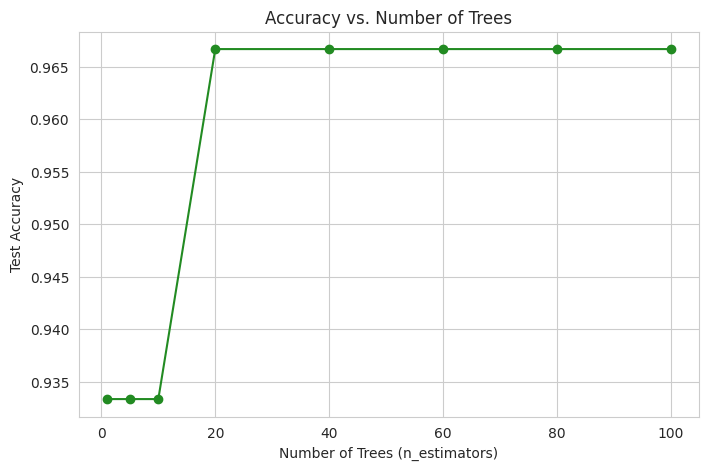

In [8]:
tree_counts = [1, 5, 10, 20, 40, 60, 80, 100]
accuracies = []

for n in tree_counts:
    rf = RandomForestScratch(n_estimators=n, max_depth=5, max_features='sqrt', random_state=42)
    rf.fit(X_train, y_train)
    preds = rf.predict(X_test)
    accuracies.append(accuracy_score(y_test, preds))

plt.figure(figsize=(8, 5))
plt.plot(tree_counts, accuracies, marker='o', color='forestgreen')
plt.title("Accuracy vs. Number of Trees")
plt.xlabel("Number of Trees (n_estimators)")
plt.ylabel("Test Accuracy")
plt.show()

## 9. Random Forest vs. a Single Decision Tree

Let's directly compare the stability of a single tree vs. the forest by retraining both on slightly different bootstrap samples and observing the variance in accuracy.

Single Tree -> mean: 0.9133, std: 0.0340
Random Forest -> mean: 0.9467, std: 0.0221


/tmp/ipykernel_481/3708600330.py:21: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([single_tree_accs, forest_accs], labels=['Single Tree', 'Random Forest'])


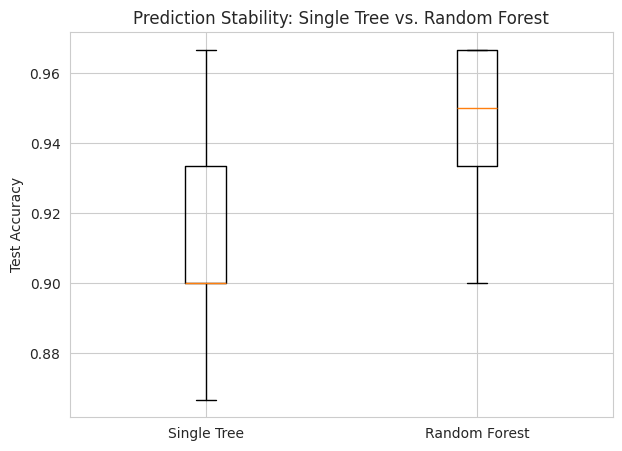

In [9]:
single_tree_accs = []
forest_accs = []

for seed in range(10):
    rng = np.random.RandomState(seed)
    idx = rng.choice(len(X_train), len(X_train), replace=True)
    X_boot, y_boot = X_train[idx], y_train[idx]

    tree = DecisionTreeScratch(max_depth=5, random_state=seed)
    tree.fit(X_boot, y_boot)
    single_tree_accs.append(accuracy_score(y_test, tree.predict(X_test)))

    forest = RandomForestScratch(n_estimators=50, max_depth=5, random_state=seed)
    forest.fit(X_boot, y_boot)
    forest_accs.append(accuracy_score(y_test, forest.predict(X_test)))

print(f"Single Tree -> mean: {np.mean(single_tree_accs):.4f}, std: {np.std(single_tree_accs):.4f}")
print(f"Random Forest -> mean: {np.mean(forest_accs):.4f}, std: {np.std(forest_accs):.4f}")

plt.figure(figsize=(7, 5))
plt.boxplot([single_tree_accs, forest_accs], labels=['Single Tree', 'Random Forest'])
plt.title("Prediction Stability: Single Tree vs. Random Forest")
plt.ylabel("Test Accuracy")
plt.show()

## 10. Model Evaluation (Full Forest)

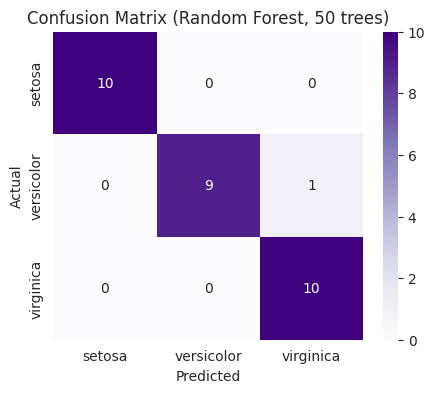

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



In [10]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples',
            xticklabels=data.target_names, yticklabels=data.target_names)
plt.title("Confusion Matrix (Random Forest, 50 trees)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

print(classification_report(y_test, y_pred, target_names=data.target_names))

## 11. Comparing with Scikit-learn's RandomForestClassifier

Let's verify our from-scratch implementation against the industry-standard library.

In [11]:
from sklearn.ensemble import RandomForestClassifier

sk_model = RandomForestClassifier(n_estimators=50, max_depth=5, random_state=42)
sk_model.fit(X_train, y_train)
sk_pred = sk_model.predict(X_test)

print("Accuracy (Scratch Model):   ", accuracy_score(y_test, y_pred))
print("Accuracy (Scikit-learn):    ", accuracy_score(y_test, sk_pred))

Accuracy (Scratch Model):    0.9666666666666667
Accuracy (Scikit-learn):     0.9


### 11.1 Feature Importance

Scikit-learn's Random Forest can report which features were most useful across all trees, based on how much each feature reduces impurity on average.

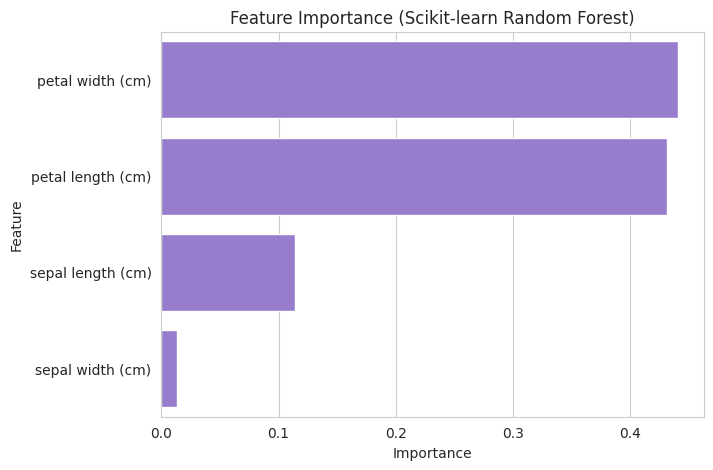

,feature,importance
3,petal width (cm),0.440597
2,petal length (cm),0.431502
0,sepal length (cm),0.114313
1,sepal width (cm),0.013588


In [12]:
importances = sk_model.feature_importances_
importance_df = pd.DataFrame({'feature': feature_names, 'importance': importances})
importance_df = importance_df.sort_values('importance', ascending=False)

plt.figure(figsize=(7, 5))
sns.barplot(data=importance_df, x='importance', y='feature', color='mediumpurple')
plt.title("Feature Importance (Scikit-learn Random Forest)")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

importance_df

## 12. Visualizing the Decision Boundary

To visualize the decision boundary, we use just 2 features (petal length & width), and compare a single tree to the forest.

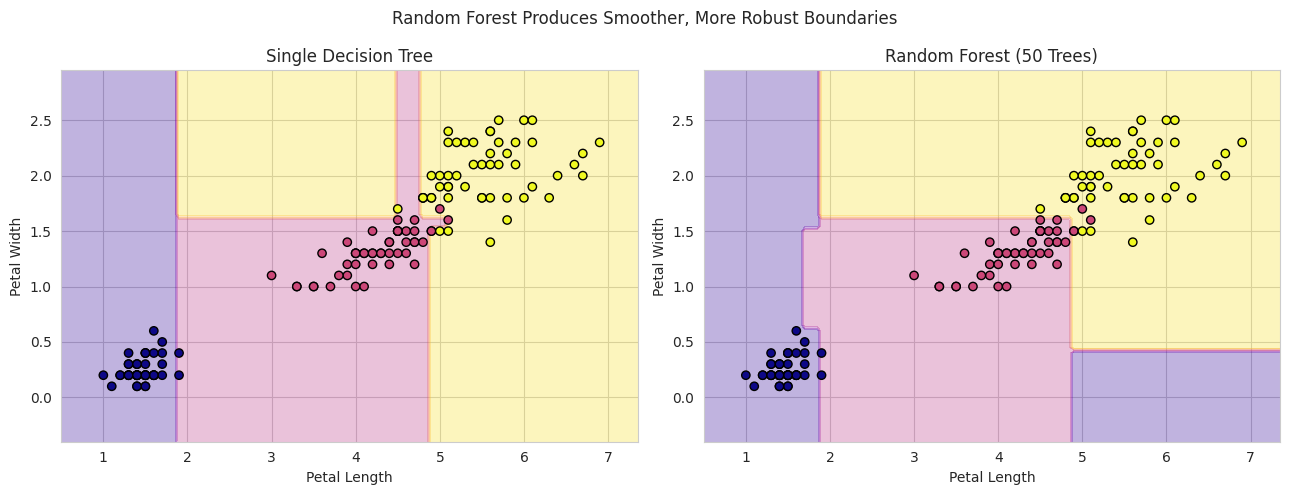

In [13]:
X2 = X[:, 2:4]  # petal length, petal width
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y, test_size=0.2, random_state=42, stratify=y
)

single_tree_2d = DecisionTreeScratch(max_depth=5, random_state=42)
single_tree_2d.fit(X2_train, y2_train)

forest_2d = RandomForestScratch(n_estimators=50, max_depth=5, random_state=42)
forest_2d.fit(X2_train, y2_train)

x_min, x_max = X2[:, 0].min() - 0.5, X2[:, 0].max() + 0.5
y_min, y_max = X2[:, 1].min() - 0.5, X2[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.05),
                      np.arange(y_min, y_max, 0.05))
grid = np.c_[xx.ravel(), yy.ravel()]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

Z_tree = single_tree_2d.predict(grid).reshape(xx.shape)
axes[0].contourf(xx, yy, Z_tree, alpha=0.3, cmap='plasma')
axes[0].scatter(X2[:, 0], X2[:, 1], c=y, cmap='plasma', edgecolors='k')
axes[0].set_title("Single Decision Tree")
axes[0].set_xlabel("Petal Length")
axes[0].set_ylabel("Petal Width")

Z_forest = forest_2d.predict(grid).reshape(xx.shape)
axes[1].contourf(xx, yy, Z_forest, alpha=0.3, cmap='plasma')
axes[1].scatter(X2[:, 0], X2[:, 1], c=y, cmap='plasma', edgecolors='k')
axes[1].set_title("Random Forest (50 Trees)")
axes[1].set_xlabel("Petal Length")
axes[1].set_ylabel("Petal Width")

plt.suptitle("Random Forest Produces Smoother, More Robust Boundaries")
plt.tight_layout()
plt.show()

## 📌 Key Takeaways

- Random Forest is a **bagging ensemble** of Decision Trees: each tree is trained on a bootstrap sample, and predictions are combined by majority vote.
- **Random feature subsampling** at each split (`max_features`, typically $\sqrt{p}$) decorrelates the trees, so their errors don't all align.
- Compared to a single Decision Tree, a Random Forest has **much lower variance** — its accuracy is far more stable across different training samples, as shown in the boxplot comparison.
- Adding more trees (`n_estimators`) generally improves stability with **diminishing returns** — accuracy plateaus after enough trees.
- Random Forests naturally provide **feature importance** scores, useful for understanding which features drive predictions.
- Like single Decision Trees, Random Forests **don't require feature scaling**.

## 🔗 Next Steps
- Explore Out-of-Bag (OOB) error estimation as a "free" validation set from the bootstrap process.
- Try Gradient Boosted Trees (XGBoost / LightGBM) — a different ensemble strategy that builds trees **sequentially** rather than independently.
- Revisit **Dimensionality Reduction (PCA)** to see how reducing features affects tree-based models compared to distance-based models like KNN.